P36 – Loan Approved or Not?

Decision Tree Classification Project
Student details:
Name      :Samar rathod
Roll No.  :B-42
Div       :D
Enrollment: 24004501210359

Problem statement
Predict whether a loan application is approved (`Loan_Status`) using applicant information such as gender, marital status, dependents,education, 
employment, income, loan amount, loan term, credit history, and property area

#IMPORT LIBRARIES

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_auc_score, RocCurveDisplay, ConfusionMatrixDisplay,roc_curve,
)
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Required libraries imported successfully!")

print("All libraries imported successfully!")

Required libraries imported successfully!
All libraries imported successfully!


#LOAD THE DATASET

In [2]:
df = pd.read_csv("train.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


Understand the Data and Create a Data Dictionary

In [3]:
print("Dataset information:")
df.info()

print("\nColumn names:")
print(df.columns.tolist())

print("\nStatistical summary:")
display(df.describe(include="all").T)

print("\nData types:")
print(df.dtypes)

data_dictionary = pd.DataFrame({
    "Column": df.columns,
    "Data Type": [str(df[col].dtype) for col in df.columns],
    "Missing Values": [df[col].isnull().sum() for col in df.columns],
    "Unique Values": [df[col].nunique() for col in df.columns]
})

display(data_dictionary)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 62.5 KB

Column names:
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantInco

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Loan_ID,614,614,LP001002,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,601,2,Male,489,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Married,611,2,Yes,398,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,599,4,0,345,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education,614,2,Graduate,480,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Self_Employed,582,2,No,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ApplicantIncome,614.0,NaN,NaN,NaN,5403.459283,6109.041673,150.0,2877.5,3812.5,5795.0,81000.0
CoapplicantIncome,614.0,NaN,NaN,NaN,1621.245798,2926.248369,0.0,0.0,1188.5,2297.25,41667.0
LoanAmount,592.0,NaN,NaN,NaN,146.412162,85.587325,9.0,100.0,128.0,168.0,700.0
Loan_Amount_Term,600.0,NaN,NaN,NaN,342.0,65.12041,12.0,360.0,360.0,360.0,480.0



Data types:
Loan_ID                  str
Gender                   str
Married                  str
Dependents               str
Education                str
Self_Employed            str
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area            str
Loan_Status              str
dtype: object


,Column,Data Type,Missing Values,Unique Values
0,Loan_ID,str,0,614
1,Gender,str,13,2
2,Married,str,3,2
3,Dependents,str,15,4
4,Education,str,0,2
5,Self_Employed,str,32,2
6,ApplicantIncome,int64,0,505
7,CoapplicantIncome,float64,0,287
8,LoanAmount,float64,22,203
9,Loan_Amount_Term,float64,14,10


Prepare the target column (Y)

Loan Status counts:
Loan_Status
Y    422
N    192
Name: count, dtype: int64

Loan Status percentages:
Loan_Status
Y    68.73
N    31.27
Name: proportion, dtype: float64


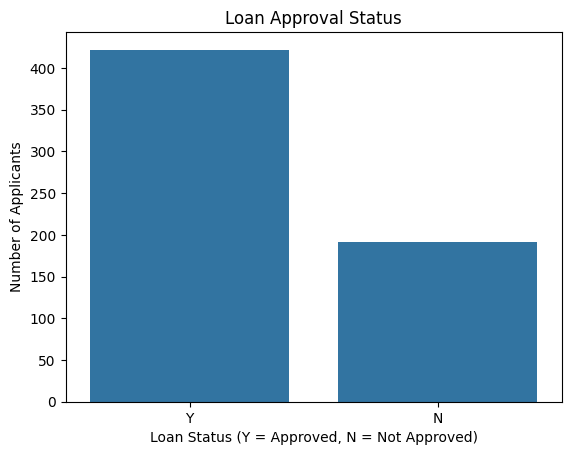

In [4]:
print("Loan Status counts:")
print(df["Loan_Status"].value_counts())

print("\nLoan Status percentages:")
print((df["Loan_Status"].value_counts(normalize=True) * 100).round(2))

sns.countplot(data=df, x="Loan_Status")
plt.title("Loan Approval Status")
plt.xlabel("Loan Status (Y = Approved, N = Not Approved)")
plt.ylabel("Number of Applicants")
plt.show()

Clean Missing Values and Create Total Income

In [5]:
df = df.drop_duplicates().copy()

# Remove the ID column because it does not describe applicant eligibility
if "Loan_ID" in df.columns:
    df.drop(columns=["Loan_ID"], inplace=True)

# Combine applicant income and co-applicant income
df["TotalIncome"] = (
    df["ApplicantIncome"] + df["CoapplicantIncome"]
)

# Standardize the target labels
df["Loan_Status"] = df["Loan_Status"].astype(str).str.strip().str.upper()

# Remove rows without a valid target
df = df[df["Loan_Status"].isin(["Y", "N"])].copy()

# Convert categorical yes/no values into consistent labels
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

print("Missing values before feature imputation:")
print(df.isnull().sum())

print("\nCleaned dataset shape:", df.shape)
display(df.head())

Missing values before feature imputation:
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
TotalIncome           0
dtype: int64

Cleaned dataset shape: (614, 13)


C:\Users\Admin\AppData\Local\Temp\ipykernel_9252\2301427267.py:19: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,TotalIncome
0,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y,5849.0
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,6091.0
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,3000.0
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,4941.0
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,6000.0


Exploratory Data Analysis (EDA) and Five Insights

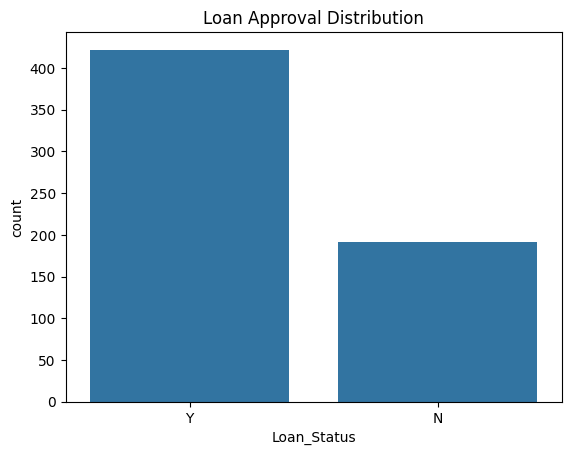

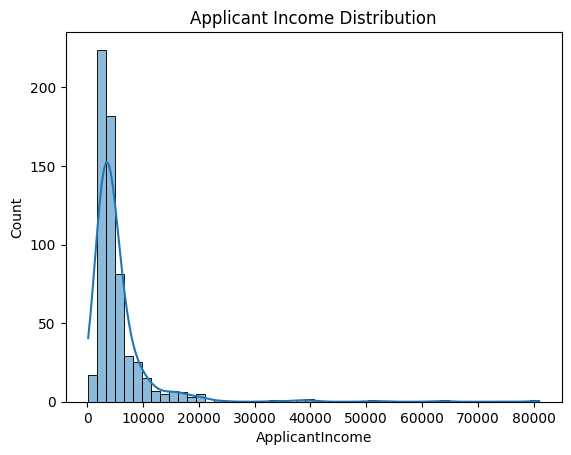

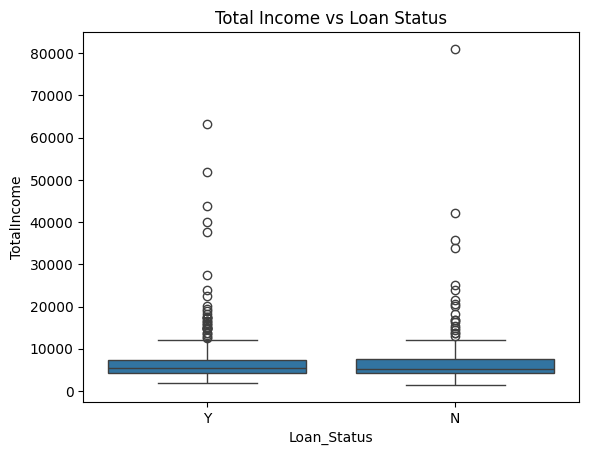

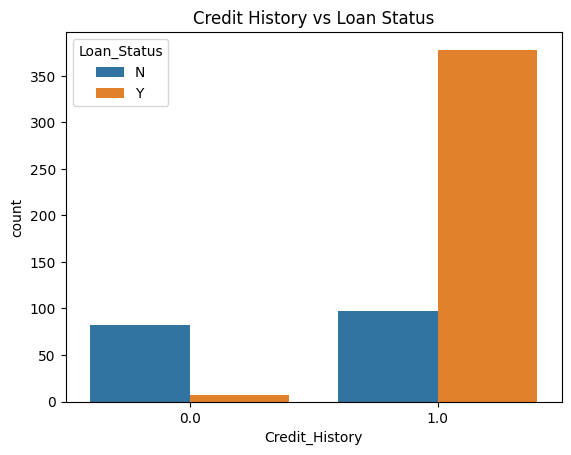

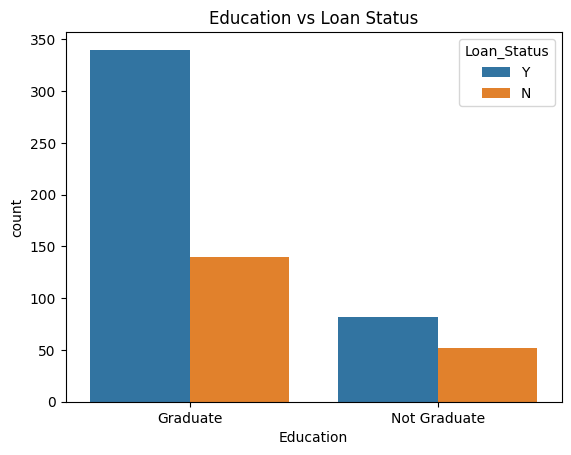

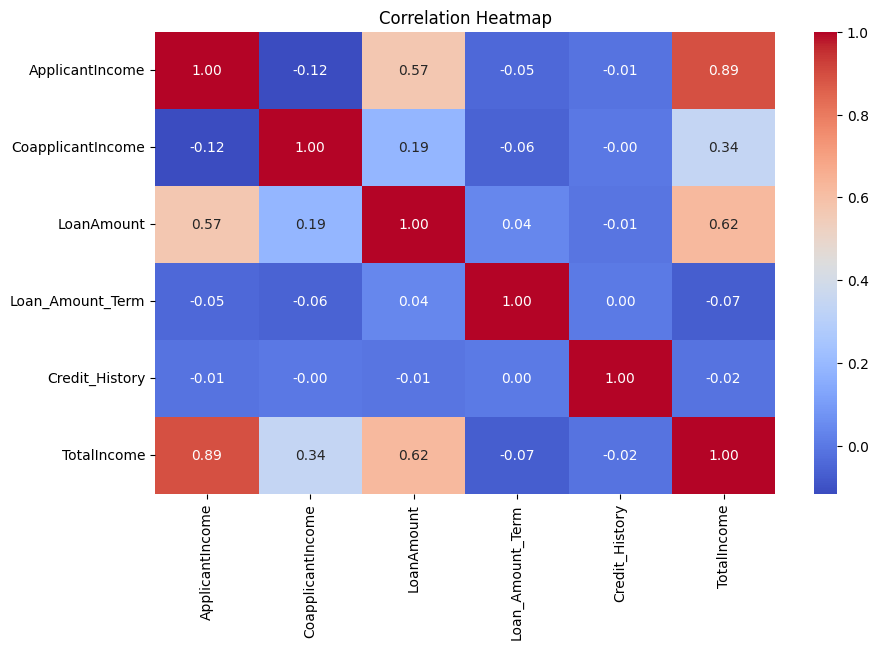

In [6]:
# 1. Loan status distribution
sns.countplot(data=df, x="Loan_Status")
plt.title("Loan Approval Distribution")
plt.show()

# 2. Applicant income distribution
sns.histplot(data=df, x="ApplicantIncome", kde=True)
plt.title("Applicant Income Distribution")
plt.show()

# 3. Total income by loan status
sns.boxplot(data=df, x="Loan_Status", y="TotalIncome")
plt.title("Total Income vs Loan Status")
plt.show()

# 4. Credit history vs loan status
sns.countplot(data=df, x="Credit_History", hue="Loan_Status")
plt.title("Credit History vs Loan Status")
plt.show()

# 5. Education vs loan status
sns.countplot(data=df, x="Education", hue="Loan_Status")
plt.title("Education vs Loan Status")
plt.show()

# Numeric correlation
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

Encode Categorical Data and Select Features

In [7]:
# Separate input features and target
X = df.drop(columns=["Loan_Status"])
y = df["Loan_Status"].map({"N": 0, "Y": 1})

# Convert categorical variables into numeric dummy columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Ensure all feature values are numeric
X = X.apply(pd.to_numeric, errors="coerce")

# Replace infinite values with missing values
X = X.replace([np.inf, -np.inf], np.nan)

print("Encoded feature shape:", X.shape)
print("Target shape:", y.shape)
display(X.head())

Encoded feature shape: (614, 15)
Target shape: (614,)


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,TotalIncome,Gender_Male,Married_Yes,Dependents_1,Dependents_2,Dependents_3+,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban
0,5849,0.0,NaN,360.0,1.0,5849.0,1,0,0,0,0,0,0,0,1
1,4583,1508.0,128.0,360.0,1.0,6091.0,1,1,1,0,0,0,0,0,0
2,3000,0.0,66.0,360.0,1.0,3000.0,1,1,0,0,0,0,1,0,1
3,2583,2358.0,120.0,360.0,1.0,4941.0,1,1,0,0,0,1,0,0,1
4,6000,0.0,141.0,360.0,1.0,6000.0,1,0,0,0,0,0,0,0,1


Split the Dataset into Training and Testing Sets

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training samples: 491
Testing samples: 123

Training target distribution:
Loan_Status
1    337
0    154
Name: count, dtype: int64

Testing target distribution:
Loan_Status
1    85
0    38
Name: count, dtype: int64


Train the Baseline Decision Tree Model

In [9]:
# Impute missing values using training data only
imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Select the best features using training data only
k = min(10, X_train_imputed.shape[1])

selector = SelectKBest(score_func=f_classif, k=k)

X_train_selected = selector.fit_transform(
    X_train_imputed, y_train
)

X_test_selected = selector.transform(X_test_imputed)

selected_features = X_train_imputed.columns[
    selector.get_support()
].tolist()

print("Selected features:")
print(selected_features)

# Train the baseline Decision Tree
baseline_model = DecisionTreeClassifier(
    random_state=42
)

baseline_model.fit(X_train_selected, y_train)

y_pred = baseline_model.predict(X_test_selected)

print("\nBaseline Model Results")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 3))
print("F1 Score:", round(f1_score(y_test, y_pred, zero_division=0), 3))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Not Approved", "Approved"],
    zero_division=0
))

Selected features:
['CoapplicantIncome', 'Loan_Amount_Term', 'Credit_History', 'TotalIncome', 'Married_Yes', 'Dependents_1', 'Dependents_2', 'Education_Not Graduate', 'Property_Area_Semiurban', 'Property_Area_Urban']

Baseline Model Results
Accuracy: 0.772
Precision: 0.813
Recall: 0.871
F1 Score: 0.841

Classification Report:
              precision    recall  f1-score   support

Not Approved       0.66      0.55      0.60        38
    Approved       0.81      0.87      0.84        85

    accuracy                           0.77       123
   macro avg       0.73      0.71      0.72       123
weighted avg       0.76      0.77      0.77       123



Compare Gini, Entropy, and Different Tree Depths

In [10]:
results = []

for criterion in ["gini", "entropy"]:
    for depth in [2, 3, 5, 7, 9, None]:

        model = DecisionTreeClassifier(
            criterion=criterion,
            max_depth=depth,
            random_state=42
        )

        model.fit(X_train_selected, y_train)
        predictions = model.predict(X_test_selected)

        results.append({
            "Criterion": criterion,
            "Max Depth": str(depth),
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "F1 Score": f1_score(
                y_test, predictions, zero_division=0
            )
        })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="F1 Score", ascending=False
    ).round(3)
)

,Criterion,Max Depth,Accuracy,Precision,Recall,F1 Score
8,entropy,5,0.854,0.838,0.976,0.902
6,entropy,2,0.854,0.845,0.965,0.901
7,entropy,3,0.854,0.853,0.953,0.900
2,gini,5,0.846,0.830,0.976,0.897
0,gini,2,0.846,0.837,0.965,0.896
1,gini,3,0.846,0.844,0.953,0.895
3,gini,7,0.829,0.814,0.976,0.888
9,entropy,7,0.829,0.814,0.976,0.888
10,entropy,9,0.829,0.820,0.965,0.886
4,gini,9,0.805,0.821,0.918,0.867


Compare Results and Select the Final Model

Selected criterion: entropy
Selected max depth: 5

Final Model Evaluation
Accuracy: 0.854
Precision: 0.838
Recall: 0.976
F1 Score: 0.902


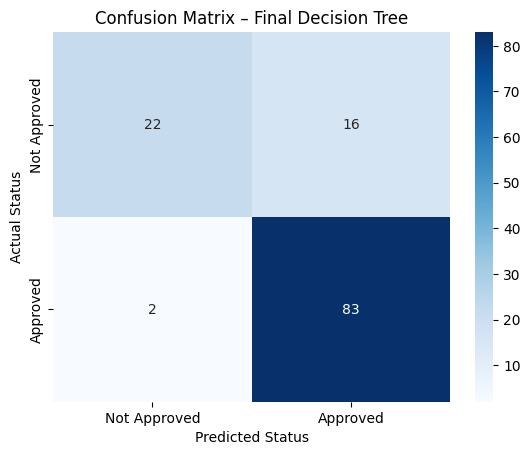

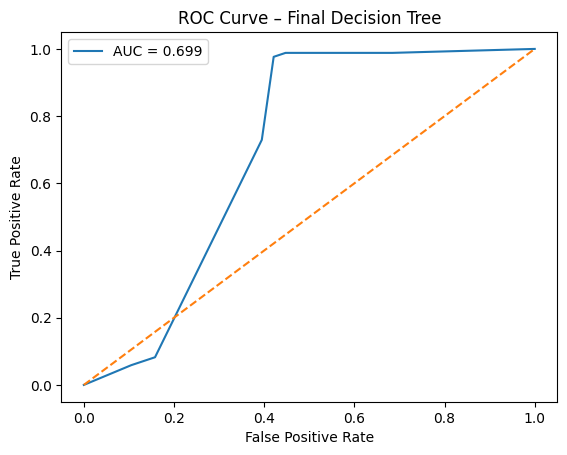

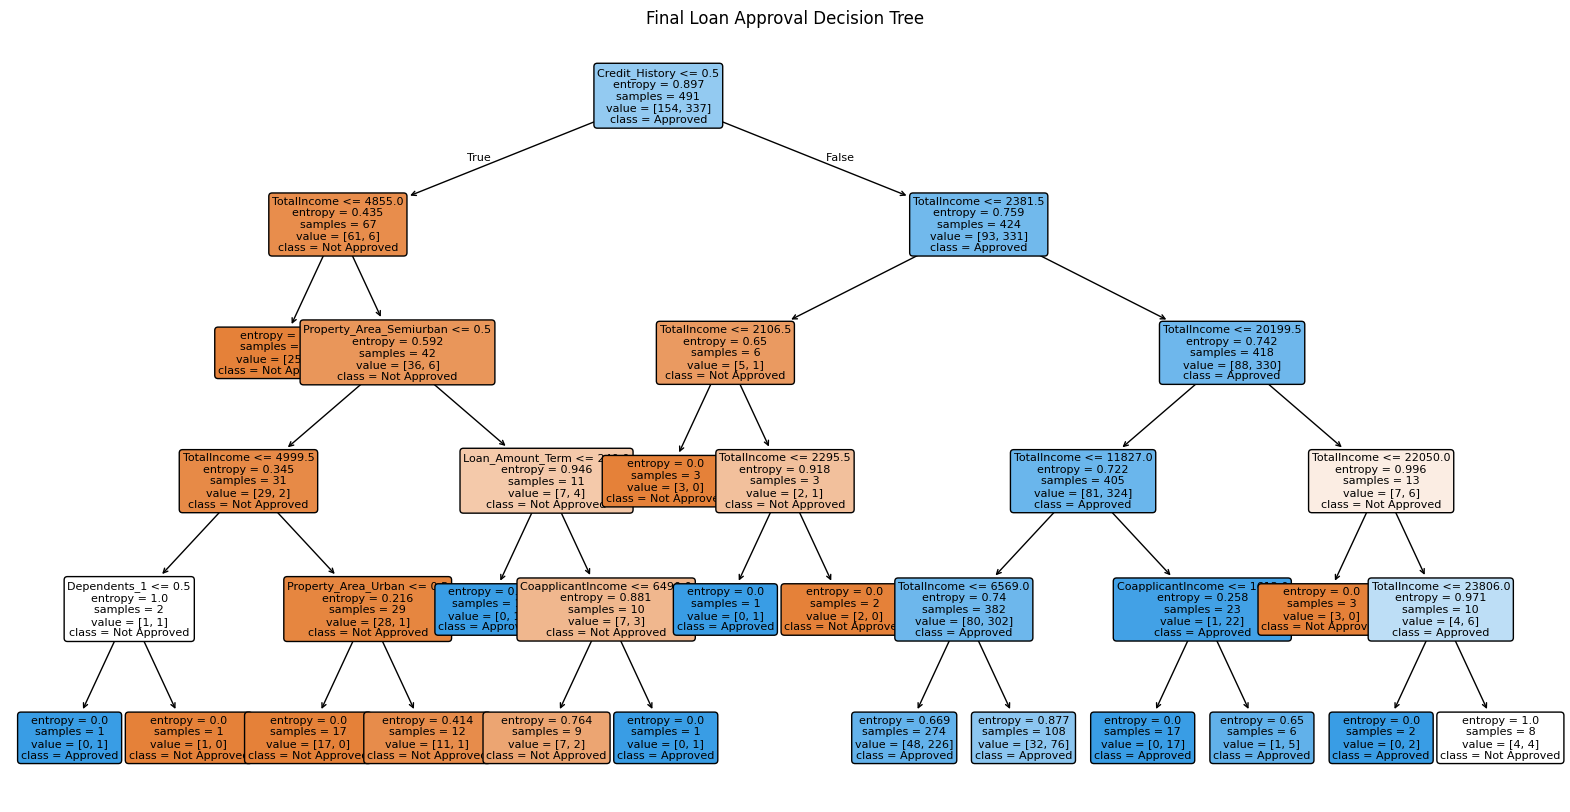

,Feature,Importance
2,Credit_History,0.646169
3,TotalIncome,0.262886
0,CoapplicantIncome,0.028610
8,Property_Area_Semiurban,0.027024
5,Dependents_1,0.014415
1,Loan_Amount_Term,0.011456
9,Property_Area_Urban,0.009440
4,Married_Yes,0.000000
7,Education_Not Graduate,0.000000
6,Dependents_2,0.000000


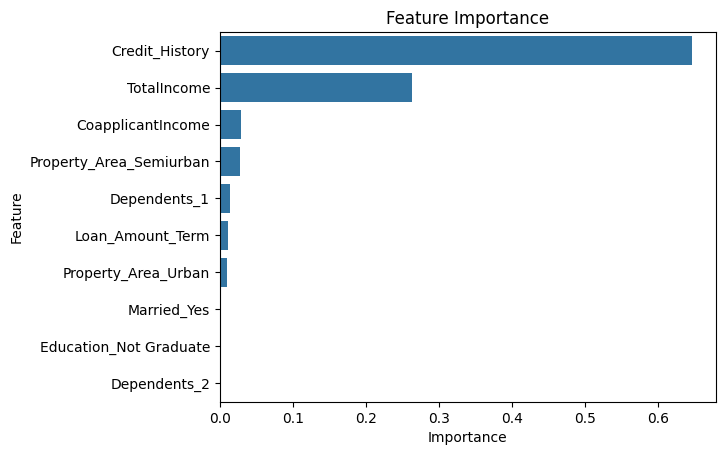

In [11]:
# Select the model with the highest F1 score
best_row = results_df.sort_values(
    by="F1 Score", ascending=False
).iloc[0]

best_criterion = best_row["Criterion"]
best_depth = best_row["Max Depth"]

if best_depth == "None":
    best_depth = None
else:
    best_depth = int(best_depth)

final_model = DecisionTreeClassifier(
    criterion=best_criterion,
    max_depth=best_depth,
    random_state=42
)

final_model.fit(X_train_selected, y_train)

final_pred = final_model.predict(X_test_selected)

print("Selected criterion:", best_criterion)
print("Selected max depth:", best_depth)

print("\nFinal Model Evaluation")
print("Accuracy:", round(accuracy_score(y_test, final_pred), 3))
print("Precision:", round(precision_score(y_test, final_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, final_pred, zero_division=0), 3))
print("F1 Score:", round(f1_score(y_test, final_pred, zero_division=0), 3))

# Confusion matrix
cm = confusion_matrix(y_test, final_pred, labels=[0, 1])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Approved", "Approved"],
    yticklabels=["Not Approved", "Approved"]
)

plt.title("Confusion Matrix – Final Decision Tree")
plt.xlabel("Predicted Status")
plt.ylabel("Actual Status")
plt.show()

# ROC curve and AUC
if len(np.unique(y_test)) == 2:
    y_probability = final_model.predict_proba(X_test_selected)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_probability)
    auc_value = roc_auc_score(y_test, y_probability)

    plt.plot(fpr, tpr, label=f"AUC = {auc_value:.3f}")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve – Final Decision Tree")
    plt.legend()
    plt.show()

# Visualize the decision tree
plt.figure(figsize=(20, 10))

plot_tree(
    final_model,
    feature_names=selected_features,
    class_names=["Not Approved", "Approved"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Final Loan Approval Decision Tree")
plt.show()

# Feature importance
importance_df = pd.DataFrame({
    "Feature": selected_features,
    "Importance": final_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df)

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance")
plt.show()

Predict Loan Approval for Three Applications

In [12]:
# Take three applications from the test dataset
three_applications = X_test_imputed.iloc[:3]

# Apply the same feature selector used during training
three_selected = selector.transform(three_applications)

# Predict loan status and probability
predictions = final_model.predict(three_selected)
probabilities = final_model.predict_proba(three_selected)[:, 1]

prediction_results = pd.DataFrame({
    "Application": ["Application 1", "Application 2", "Application 3"],
    "Predicted Loan Status": [
        "Approved" if p == 1 else "Not Approved"
        for p in predictions
    ],
    "Approval Probability (%)": (probabilities * 100).round(2)
})

display(prediction_results)

,Application,Predicted Loan Status,Approval Probability (%)
0,Application 1,Not Approved,0.00
1,Application 2,Approved,82.48
2,Application 3,Approved,70.37


Conclusion and Prepare the PDF Report

In [13]:
print("P36 – Loan Approved or Not?")

print("\nConclusion:")
print(
    "A Decision Tree classification model was developed to predict "
    "loan approval using applicant information."
)

print("\nSelected criterion:", best_criterion)
print("Selected maximum depth:", best_depth)
print("Accuracy:", round(accuracy_score(y_test, final_pred), 3))
print(
    "Precision:",
    round(precision_score(y_test, final_pred, zero_division=0), 3)
)
print(
    "Recall:",
    round(recall_score(y_test, final_pred, zero_division=0), 3)
)
print(
    "F1 Score:",
    round(f1_score(y_test, final_pred, zero_division=0), 3)
)

print("\nSelected features:", selected_features)

print(
    "\nThe model's predictions are based on historical data and should "
    "not be used as the sole basis for real loan decisions."
)

P36 – Loan Approved or Not?

Conclusion:
A Decision Tree classification model was developed to predict loan approval using applicant information.

Selected criterion: entropy
Selected maximum depth: 5
Accuracy: 0.854
Precision: 0.838
Recall: 0.976
F1 Score: 0.902

Selected features: ['CoapplicantIncome', 'Loan_Amount_Term', 'Credit_History', 'TotalIncome', 'Married_Yes', 'Dependents_1', 'Dependents_2', 'Education_Not Graduate', 'Property_Area_Semiurban', 'Property_Area_Urban']

The model's predictions are based on historical data and should not be used as the sole basis for real loan decisions.


**Conclusion:**
The Decision Tree model predicts whether a loan may be approved or rejected. It achieved 85.4% accuracy in the saved results. I learned how to clean data, train a machine learning model, and evaluate its performance. The model can make mistakes, so it should not be the only basis for loan approval.
